# ESE 5420 Final Project
## What defines quality for a bottle of Portuguese wine?
**By:** Alan Lin

## Baseline (deliverable by baseline checkpoint on 11/9)

We begin by importing all necessary libraries and dependencies.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.linear_model import LinearRegression, Lasso, lasso_path
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

We next read in the two files: one for red wines and the other for white wines.

In [2]:
red_df = pd.read_csv('wine+quality/winequality-red.csv', sep = ';')

red_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [3]:
white_df = pd.read_csv('wine+quality/winequality-white.csv', sep = ';')

white_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


We will now proceed by implementing the instructor's suggestions with data cleaning: that is, we will remove the duplicate rows and count the wines at each quality score. The data is already split by color, so that will remain as is. 

In [4]:
print('Number of red wine duplicates:', np.sum(red_df.duplicated()))
print('Number of white wine duplicates:', np.sum(white_df.duplicated()))

Number of red wine duplicates: 240
Number of white wine duplicates: 937


In [5]:
cleaned_red_df = red_df.drop_duplicates(ignore_index = True)

cleaned_red_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1354,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1355,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1356,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1357,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [6]:
cleaned_white_df = white_df.drop_duplicates(ignore_index = True)

cleaned_white_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.99490,3.18,0.47,9.6,6
...,...,...,...,...,...,...,...,...,...,...,...,...
3956,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
3957,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
3958,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
3959,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [7]:
reds_by_quality = cleaned_red_df.groupby('quality').size().reset_index(name = 'total_rows')
reds_by_quality

,quality,total_rows
0,3,10
1,4,53
2,5,577
3,6,535
4,7,167
5,8,17


In [8]:
whites_by_quality = cleaned_white_df.groupby('quality').size().reset_index(name = 'total_rows')
whites_by_quality

,quality,total_rows
0,3,20
1,4,153
2,5,1175
3,6,1788
4,7,689
5,8,131
6,9,5


## Begin Model Training with Linear Regression
We begin by fitting a basic linear regression on each of our datasets. We will use 10-fold CV for each model, and report the Mean Absolute Error (MAE) for cross validation with the fold spread beside the median predictor. Since we only have a few instances of very high and very low "quality" scores for both red and white wines, we will stratify our train-test splits to account for that.

In [9]:
red_y = cleaned_red_df['quality']
red_X = cleaned_red_df.drop(columns = 'quality')

white_y = cleaned_white_df['quality']
white_X = cleaned_white_df.drop(columns = 'quality')

Create an 80/20 train-test split (as suggested by Prof Preciado) and set a random state for replicability.

In [10]:
red_X_train, red_X_test, red_y_train, red_y_test = train_test_split(
    red_X, red_y, test_size = 0.2, random_state = 27, stratify = np.clip(red_y, 4, 7)
)

white_X_train, white_X_test, white_y_train, white_y_test = train_test_split(
    white_X, white_y, test_size = 0.2, random_state = 27, stratify = np.clip(white_y, 4, 8)
)

Now that we have split our data, we can proceed to fit our linear regression with 10-fold CV (for which we will use StratifiedKFold to assist with the imbalanced classes).

In [11]:
# Set up the 10-fold CV
skf = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 27)
red_splits = list(skf.split(red_X_train, np.clip(red_y_train, 4, 7))) # folds built from strat labels

# Run 10-fold stratified CV for our linear regression and get the MAE metrics
red_lr_mae  = -cross_val_score(LinearRegression(), red_X_train, red_y_train, cv=red_splits,
                               scoring="neg_mean_absolute_error")

# Run 10-fold stratified CV for our "dummy" regression that just predicts the median and get the
# MAE metrics
red_med_mae = -cross_val_score(DummyRegressor(strategy="median"), red_X_train, red_y_train,
                               cv=red_splits, scoring="neg_mean_absolute_error")

print(f'''--- Results for Red Wines ---
Linear Regression MAE metrics:
Mean: {red_lr_mae.mean()}
Median: {np.median(red_lr_mae)}
Std: {red_lr_mae.std()}
Range: ({red_lr_mae.min()}, {red_lr_mae.max()}) \n''')

print(f'''Dummy Regressor MAE metrics:
Mean: {red_med_mae.mean()}
Median: {np.median(red_med_mae)}
Std: {red_med_mae.std()}
Range: ({red_med_mae.min()}, {red_med_mae.max()})''')

--- Results for Red Wines ---
Linear Regression MAE metrics:
Mean: 0.5121836921209509
Median: 0.5105634394315114
Std: 0.03136167290899036
Range: (0.45575019691878654, 0.553970649883388) 

Dummy Regressor MAE metrics:
Mean: 0.6715936119605843
Median: 0.6759259259259259
Std: 0.011726855435538539
Range: (0.6513761467889908, 0.6880733944954128)


In [12]:
# Set up the 10-fold CV
skf = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 27)
white_splits = list(skf.split(white_X_train, np.clip(white_y_train, 4, 8))) # folds built from strat labels

# Run 10-fold stratified CV for our linear regression and get the MAE metrics
white_lr_mae  = -cross_val_score(LinearRegression(), white_X_train, white_y_train, cv=white_splits,
                                 scoring="neg_mean_absolute_error")

# Run 10-fold stratified CV for our "dummy" regression that just predicts the median and get the
# MAE metrics
white_med_mae = -cross_val_score(DummyRegressor(strategy="median"), white_X_train, white_y_train,
                                 cv=white_splits, scoring="neg_mean_absolute_error")

print(f'''--- Results for White Wines ---
Linear Regression MAE metrics:
Mean: {white_lr_mae.mean()}
Median: {np.median(white_lr_mae)}
Std: {white_lr_mae.std()}
Range: ({white_lr_mae.min()}, {white_lr_mae.max()}) \n''')

print(f'''Dummy Regressor MAE metrics:
Mean: {white_med_mae.mean()}
Median: {np.median(white_med_mae)}
Std: {white_med_mae.std()}
Range: ({white_med_mae.min()}, {white_med_mae.max()})''')

--- Results for White Wines ---
Linear Regression MAE metrics:
Mean: 0.5823291178679771
Median: 0.5881833162971846
Std: 0.016362883952717643
Range: (0.5399498959412484, 0.6013091874456168) 

Dummy Regressor MAE metrics:
Mean: 0.6328894301800903
Median: 0.6340694006309149
Std: 0.00270792711058976
Range: (0.6265822784810127, 0.637223974763407)


We run a LASSO model using 10-Fold CV over a log-grid from $10^{-4}$ to $10$ while scaling inside the folds to select the penalty $\alpha$ chosen for our LASSO model. We will print out the selected $\alpha$ for both types of wines.

In [13]:
inner = KFold(n_splits=10, shuffle=True, random_state=27)

lasso = make_pipeline(
    StandardScaler(),
    GridSearchCV(
        Lasso(max_iter=10000),
        param_grid={"alpha": np.logspace(-4, 1, 50)},
        cv=inner,
        scoring="neg_mean_absolute_error",
    ),
)

red_lasso_mae = -cross_val_score(lasso, red_X_train, red_y_train, cv=red_splits,
                                    scoring="neg_mean_absolute_error")
white_lasso_mae = -cross_val_score(lasso, white_X_train, white_y_train, cv=white_splits,
                                    scoring="neg_mean_absolute_error")

print(f'''--- Red Wines LASSO MAE Metrics ---
Mean: {red_lasso_mae.mean()}
Median: {np.median(red_lasso_mae)}
Std: {red_lasso_mae.std()}
Range: ({red_lasso_mae.min()}, {red_lasso_mae.max()}) \n''')

print(f'''Dummy Regressor MAE metrics:
Mean: {white_lasso_mae.mean()}
Median: {np.median(white_lasso_mae)}
Std: {white_lasso_mae.std()}
Range: ({white_lasso_mae.min()}, {white_lasso_mae.max()})''')

--- Red Wines LASSO MAE Metrics ---
Mean: 0.5125744780718484
Median: 0.5109238013981905
Std: 0.03064874247299016
Range: (0.45735255577639533, 0.5534001818633838) 

Dummy Regressor MAE metrics:
Mean: 0.5823688722817462
Median: 0.5881839062344131
Std: 0.016383854277383238
Range: (0.5399147331871926, 0.6011143570619619)


We now take follow Professor Preciado's instruction and fit a LASSO path, then plot the order in which our predictors enter as well as the CV $\alpha$ selected, as a preview of the key figure.

Red entry order:
  1. alcohol  (enters at alpha = 0.343)
  2. volatile acidity  (enters at alpha = 0.2719)
  3. sulphates  (enters at alpha = 0.152)
  4. total sulfur dioxide  (enters at alpha = 0.07565)
  5. chlorides  (enters at alpha = 0.06734)
  6. pH  (enters at alpha = 0.03765)
  7. density  (enters at alpha = 0.02364)
  8. free sulfur dioxide  (enters at alpha = 0.01322)
  9. citric acid  (enters at alpha = 0.01048)
  10. residual sugar  (enters at alpha = 0.003275)
  11. fixed acidity  (enters at alpha = 0.0001592)


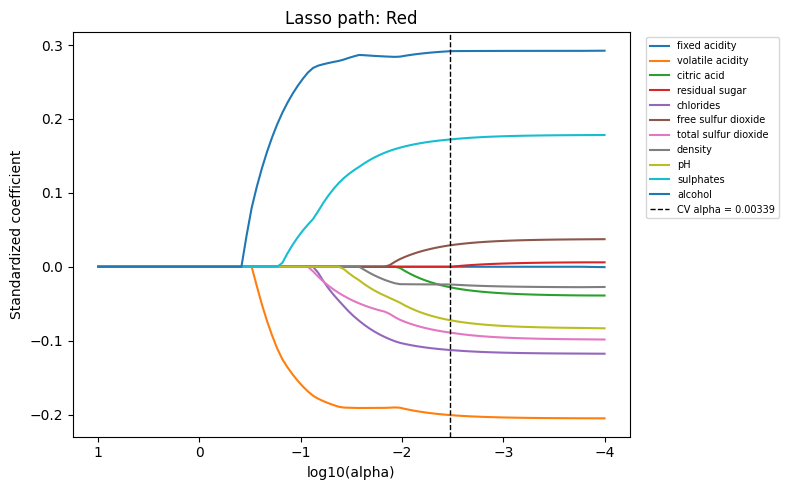




White entry order:
  1. alcohol  (enters at alpha = 0.3854)
  2. volatile acidity  (enters at alpha = 0.1707)
  3. pH  (enters at alpha = 0.07565)
  4. fixed acidity  (enters at alpha = 0.06734)
  5. free sulfur dioxide  (enters at alpha = 0.06734)
  6. chlorides  (enters at alpha = 0.05337)
  7. residual sugar  (enters at alpha = 0.04751)
  8. sulphates  (enters at alpha = 0.04751)
  9. citric acid  (enters at alpha = 0.01874)
  10. total sulfur dioxide  (enters at alpha = 0.01485)
  11. density  (enters at alpha = 0.01485)


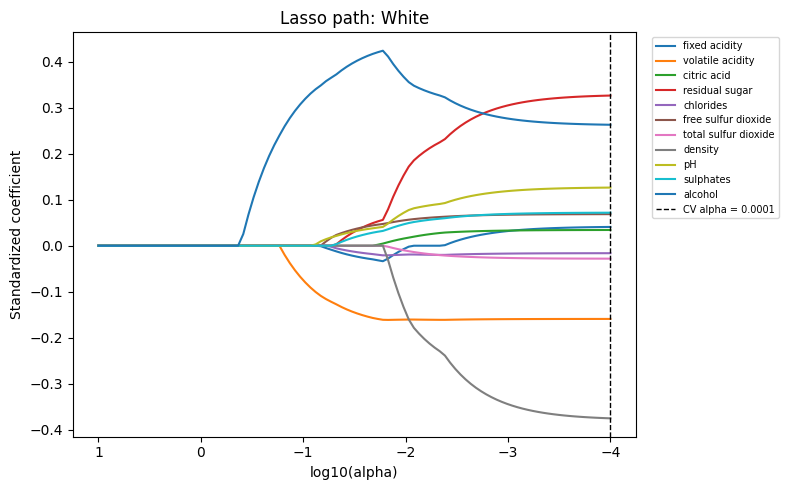

In [14]:
alpha_grid = np.logspace(-4, 1, 100)   # lasso_path sorts these from large to small

def plot_lasso_path(X_train, y_train, title, mark_best_alpha=True):
    names = list(X_train.columns)
    Xs = StandardScaler().fit_transform(X_train)
    yc = np.asarray(y_train) - np.mean(y_train)      # lasso_path has no intercept

    alphas, coefs, _ = lasso_path(Xs, yc, alphas=alpha_grid, max_iter=10000)

    # Entry order: the largest alpha at which each coefficient is nonzero
    entry_alpha = np.array([
        alphas[np.nonzero(coefs[j])[0][0]] if np.any(coefs[j]) else 0.0
        for j in range(len(names))
    ])
    order = np.argsort(-entry_alpha)
    print(f"{title} entry order:")
    for rank, j in enumerate(order, 1):
        print(f"  {rank}. {names[j]}  (enters at alpha = {entry_alpha[j]:.4g})")

    fig, ax = plt.subplots(figsize=(8, 5))
    for j in range(len(names)):
        ax.plot(np.log10(alphas), coefs[j], label=names[j])

    if mark_best_alpha:
        gs = GridSearchCV(Lasso(max_iter=10000),
                          {"alpha": np.logspace(-4, 1, 50)},
                          cv=KFold(10, shuffle=True, random_state=27),
                          scoring="neg_mean_absolute_error").fit(Xs, y_train)
        best = gs.best_params_["alpha"]
        ax.axvline(np.log10(best), color="k", ls="--", lw=1,
                   label=f"CV alpha = {best:.3g}")

    ax.invert_xaxis()                                 # strong penalty on the left
    ax.set_xlabel("log10(alpha)")
    ax.set_ylabel("Standardized coefficient")
    ax.set_title(f"Lasso path: {title}")
    ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    plt.show()

plot_lasso_path(red_X_train, red_y_train, "Red")
print('\n\n')
plot_lasso_path(white_X_train, white_y_train, "White")

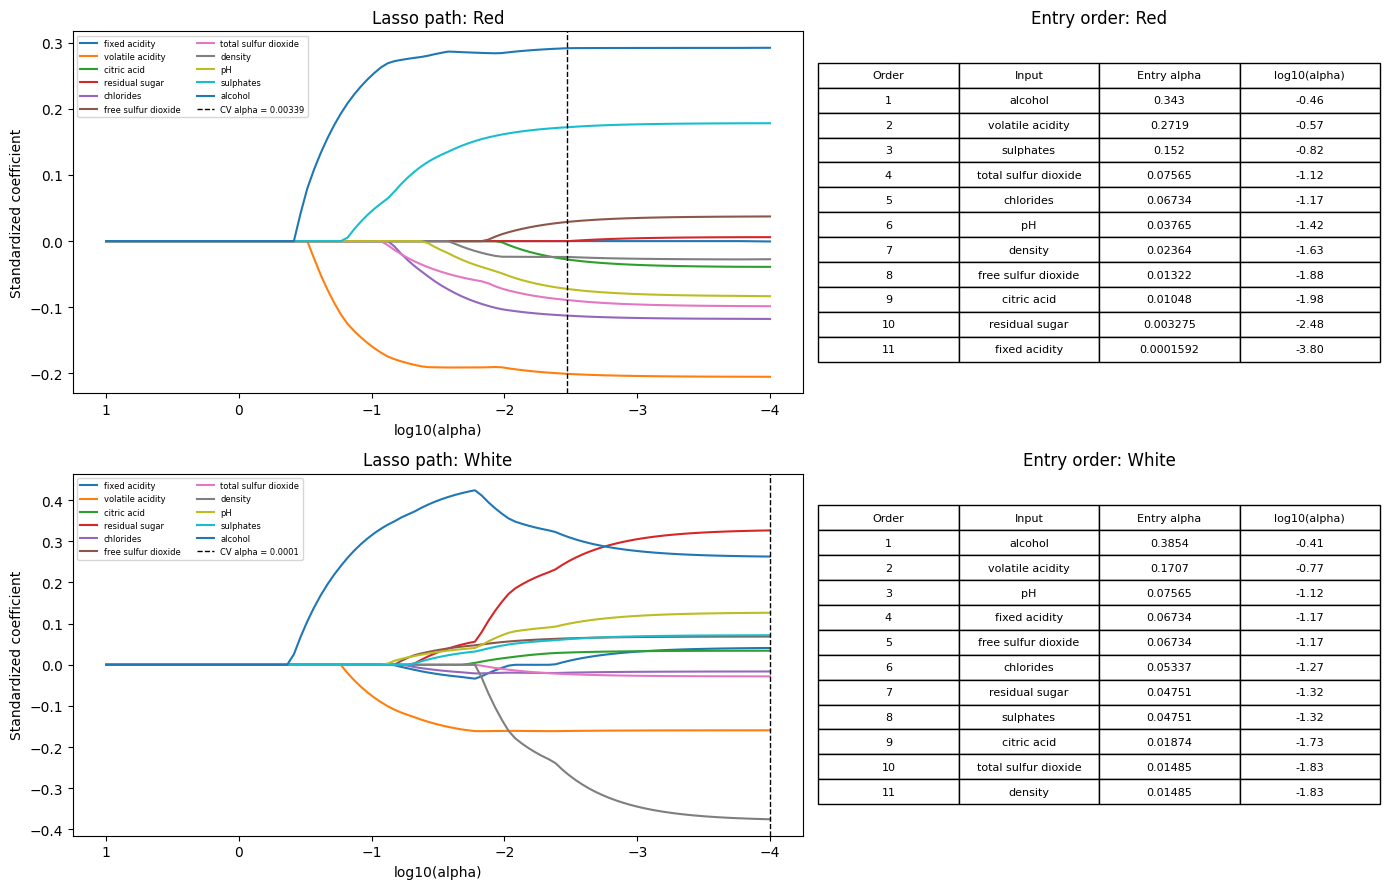

In [15]:
alpha_grid = np.logspace(-4, 1, 100)

def compute_path(X_train, y_train):
    names = list(X_train.columns)
    Xs = StandardScaler().fit_transform(X_train)
    yc = np.asarray(y_train) - np.mean(y_train)
    alphas, coefs, _ = lasso_path(Xs, yc, alphas=alpha_grid, max_iter=10000)

    entry_alpha = np.array([
        alphas[np.nonzero(coefs[j])[0][0]] if np.any(coefs[j]) else 0.0
        for j in range(len(names))
    ])
    order = np.argsort(-entry_alpha)

    gs = GridSearchCV(Lasso(max_iter=10000),
                      {"alpha": np.logspace(-4, 1, 50)},
                      cv=KFold(10, shuffle=True, random_state=27),
                      scoring="neg_mean_absolute_error").fit(Xs, y_train)
    best = gs.best_params_["alpha"]
    return names, alphas, coefs, entry_alpha, order, best

def draw_path(ax, names, alphas, coefs, best, title):
    for j in range(len(names)):
        ax.plot(np.log10(alphas), coefs[j], label=names[j])
    ax.axvline(np.log10(best), color="k", ls="--", lw=1,
               label=f"CV alpha = {best:.3g}")
    ax.invert_xaxis()                      # strong penalty on the left
    ax.set_xlabel("log10(alpha)")
    ax.set_ylabel("Standardized coefficient")
    ax.set_title(f"Lasso path: {title}")
    ax.legend(fontsize=6, loc="upper left", ncol=2)

def draw_table(ax, names, entry_alpha, order, title):
    ax.axis("off")
    rows = [[rank, names[j],
             f"{entry_alpha[j]:.4g}",
             f"{np.log10(entry_alpha[j]):.2f}" if entry_alpha[j] > 0 else "never"]
            for rank, j in enumerate(order, 1)]
    tbl = ax.table(cellText=rows,
                   colLabels=["Order", "Input", "Entry alpha", "log10(alpha)"],
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)
    tbl.scale(1, 1.3)
    ax.set_title(f"Entry order: {title}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9),
                         gridspec_kw={"width_ratios": [1.3, 1]})

for row, (X_tr, y_tr, label) in enumerate([
        (red_X_train, red_y_train, "Red"),
        (white_X_train, white_y_train, "White")]):
    names, alphas, coefs, entry_alpha, order, best = compute_path(X_tr, y_tr)
    draw_path(axes[row, 0], names, alphas, coefs, best, label)
    draw_table(axes[row, 1], names, entry_alpha, order, label)

fig.tight_layout()
plt.show()
fig.savefig("lasso_path_summary.png", dpi=200, bbox_inches="tight")

We can see that for both types of wine, alcohol and volatile acidity are the two most correlated with quality score. After these two predictors enter, the remaining are correlated differently with quality score across the two types of wines. 

### Acknowledgements
I would like to thank the UC Irvine Machine Learning Repository for generously sharing databases with the public for free usage. The citation for this dataset in IEEE format is here: 

P. Cortez, A. Cerdeira, F. Almeida, T. Matos, and J. Reis. "Wine Quality," UCI Machine Learning Repository, 2009. [Online]. Available: https://doi.org/10.24432/C56S3T.


I would also like to attribute some of my code in this file to Claude Sonnet 5.5 on Medium effort. While I wrote the majority of the code, the AI model helped me debug my errors and gave me suggestions on how to approach the two plots for this deliverable objective.